# Plotting all the quantities that `goldsluice` has computed

*A fourth example for the `goldpan` / `goldsluice` note. Draft prepared with Claude Code for A. Villano, 2026-10-28.*

This notebook reads back every quantity (RQ) of the run of `goldsluice/examples/r76-registry.dataset.toml` on the Run 76 series `07221203_2025` (Side-2 readout, 30 dumps, 81,992 events, six phonon channels) and plots each of them. It never touches the raw data. The processed files are not in the repository: to make them, run `python -m goldsluice run r76-registry.dataset.toml` in `goldsluice/examples/` (a few minutes).

The six algorithms of the definition file give nine quantities for each channel:

| algorithm | quantities | what they are |
|---|---|---|
| `peak` | `adc_max`, `current_max` | the largest ADC value; the largest value above the baseline (ADC counts: `amps_per_adc` is a placeholder equal to 1) |
| `max_time` | `max_time_s` | when the largest sample happens, from the start of the trace |
| `baseline` | `baseline_mean`, `baseline_std` | the mean and the standard deviation of the pretrigger window |
| `excursion` | `max_deviation`, `excursion_ratio` | the largest distance from the baseline after the window; that, over the window's standard deviation |
| `integral` | `integral` | the area of the baseline-subtracted trace (ADC counts times seconds) |
| `rise_time` | `rise_time_s` | the 10 to 90 % rise time of the largest pulse |

Needs `goldpan` (installed by `requirements.txt`). Run with the `darkmatter_cli_env` kernel.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from goldpan.dataset import Dataset

In [2]:
# Find the definition file by walking up to the repository's goldsluice/examples folder.
_here = Path.cwd().resolve()
EXAMPLES = next(p / "goldsluice" / "examples" for p in [_here, *_here.parents] if (p / "goldsluice" / "examples").is_dir())

ds = Dataset.open(EXAMPLES / "r76-registry.dataset.toml")
q = ds.processed()                                  # only the processed quantities, no pulses: small and fast
channels = list(q.quantities.fields[3:])            # after the keys series, dump, event: one record per channel
names = list(q.quantities[channels[0]].fields)      # the quantities, the same for every channel

print(q)
print("channels:  ", channels)
print("quantities:", names)

Events(detector='NAI-S2', n_events=81992, traces=[], quantities=['series', 'dump', 'event', 'Side2pC', 'Side2pF', 'Side2pE', 'Side2pB', 'Side2pA', 'Side2pD'])
channels:   ['Side2pC', 'Side2pF', 'Side2pE', 'Side2pB', 'Side2pA', 'Side2pD']
quantities: ['adc_max', 'current_max', 'max_time_s', 'baseline_mean', 'baseline_std', 'max_deviation', 'excursion_ratio', 'integral', 'rise_time_s']


In [3]:
# One plain array per channel and quantity, and the dump of every event.
rq = {(ch, n): np.asarray(q.quantities[ch][n], dtype=float) for ch in channels for n in names}
dump = np.asarray(q.quantities["dump"])

# How to draw each quantity: its label, the factor to a convenient unit, and whether a log axis suits it.
INFO = {
    "adc_max":         ("largest ADC value (counts)", 1, "lin"),
    "current_max":     ("largest value above baseline (counts)", 1, "log"),
    "max_time_s":      ("time of the largest sample (ms)", 1e3, "lin"),
    "baseline_mean":   ("baseline mean (counts)", 1, "lin"),
    "baseline_std":    ("baseline standard deviation (counts)", 1, "log"),
    "max_deviation":   ("largest distance from baseline after the window (counts)", 1, "log"),
    "excursion_ratio": ("largest distance over baseline std", 1, "log"),
    "integral":        ("integral of the baseline-subtracted trace (counts s)", 1, "lin"),
    "rise_time_s":     ("10-90 % rise time (us)", 1e6, "log"),
}
assert set(INFO) == set(names), set(names) ^ set(INFO)   # a new algorithm in the definition file needs a line in INFO

# The median of every quantity, per channel; and how many events have no value (nan).
print(f"{'':16}" + "".join(f"{ch:>12}" for ch in channels))
for n in names:
    print(f"{n:16}" + "".join(f"{np.nanmedian(rq[ch, n]) * INFO[n][1]:>12.4g}" for ch in channels))
print()
for ch in channels:
    for n in names:
        k = int(np.isnan(rq[ch, n]).sum())
        if k:
            print(f"{ch} {n}: {k:,} events without a value ({k / len(dump):.1%})")

                     Side2pC     Side2pF     Side2pE     Side2pB     Side2pA     Side2pD
adc_max                 3423        3703        3526        3935        4143        3753
current_max            196.7       385.3         257       580.4       783.8       448.6
max_time_s            0.5024      0.4936      0.4976      0.4928       0.476        0.48
baseline_mean           3174        3234        3201        3242        3224        3225
baseline_std            1.55       6.186       1.823       5.393       6.206       7.264
max_deviation          196.3       387.2       258.4       578.4       783.9       449.1
excursion_ratio        118.1       28.91       41.04       35.62       38.47        24.3
integral              0.1919      0.3598      0.2456        0.42      0.4721      0.3694
rise_time_s               32        20.8        26.4          24        22.4        25.6

Side2pC rise_time_s: 4,462 events without a value (5.4%)
Side2pF rise_time_s: 1,614 events without a value (2

## Every quantity, all six channels

One panel per quantity, the six channels overlaid. The axes are logarithmic where the quantity is spread over orders of magnitude (the pulses), linear where it is not.

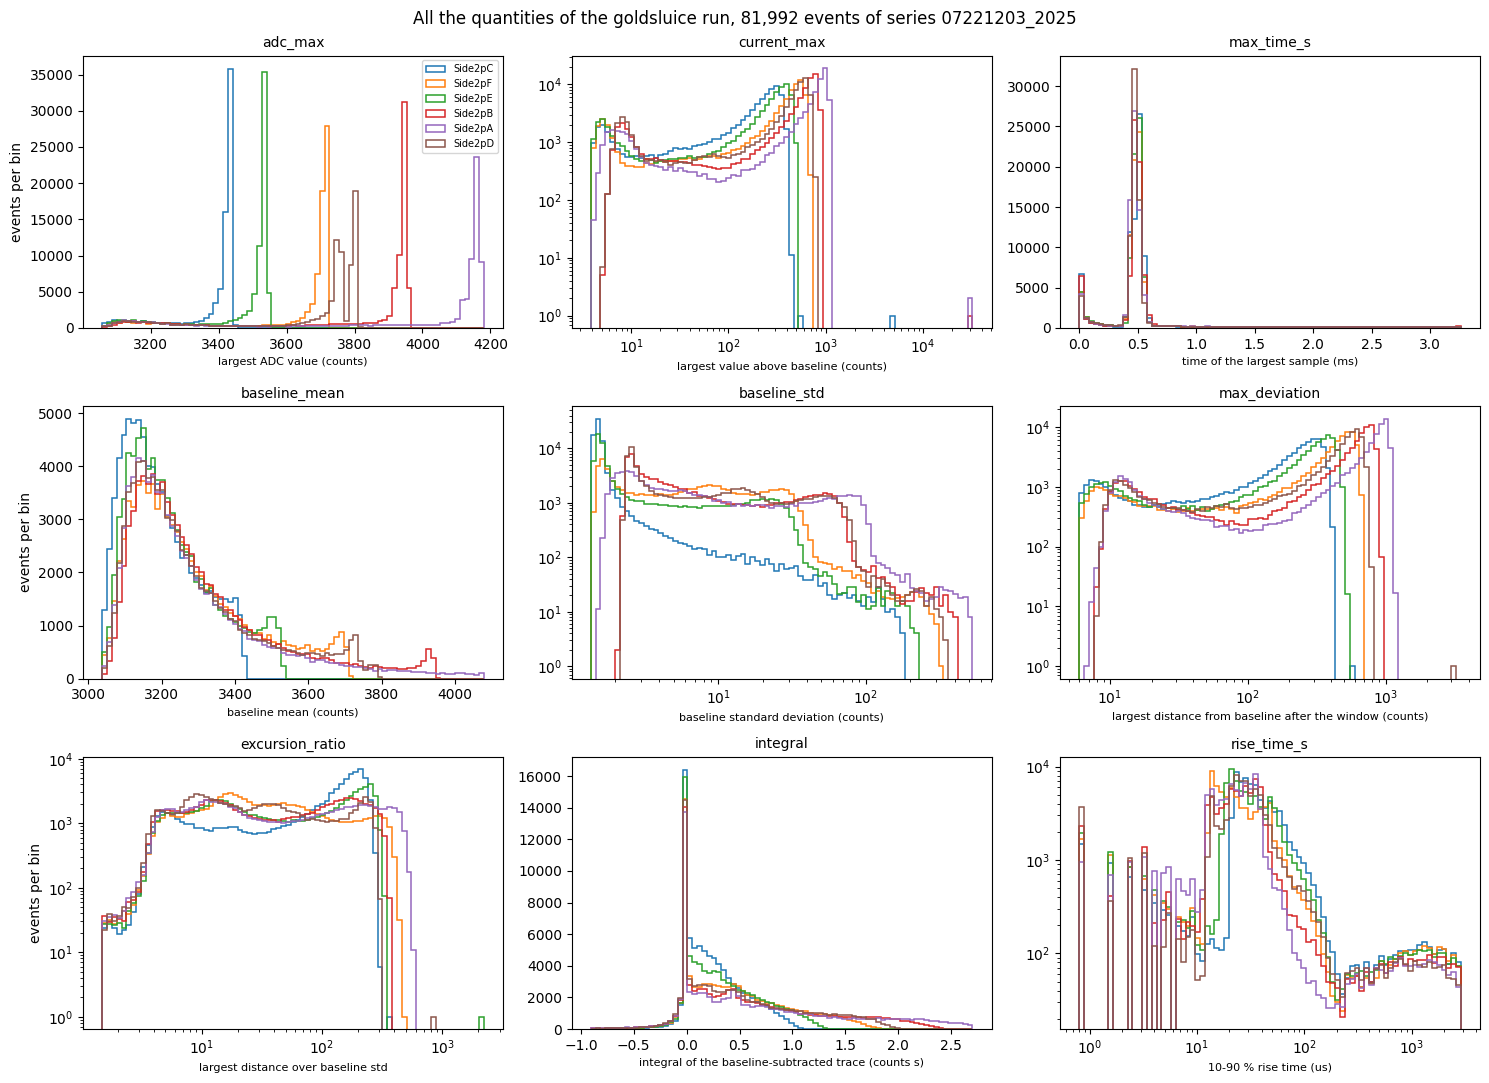

In [4]:
def edges(values, scale, n=80):
    """Bin edges for a quantity: its 0.2 to 99.8 percent range (the top of the range for a log axis), in log or linear steps."""
    v = values[np.isfinite(values)]
    if scale == "log":
        v = v[v > 0]
        return np.logspace(np.log10(np.percentile(v, 0.2)), np.log10(v.max()), n)
    return np.linspace(*np.percentile(v, [0.2, 99.8]), n)

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, n in zip(axes.flat, names):
    label, f, scale = INFO[n]
    allv = np.concatenate([rq[ch, n] for ch in channels]) * f
    bins = edges(allv, scale)
    for ch in channels:
        ax.hist(rq[ch, n] * f, bins=bins, histtype="step", lw=1.1, label=ch)
    if scale == "log":
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_xlabel(label, fontsize=8)
    ax.set_title(n, fontsize=10)
axes[0, 0].legend(fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel("events per bin")
fig.suptitle(f"All the quantities of the goldsluice run, {len(dump):,} events of series 07221203_2025", fontsize=12)
fig.tight_layout()
plt.show()

## One quantity against another

The quantities are not independent: three of them measure the size of the pulse in different ways (`current_max`, `max_deviation`, `integral`). For one channel, each against `current_max`.

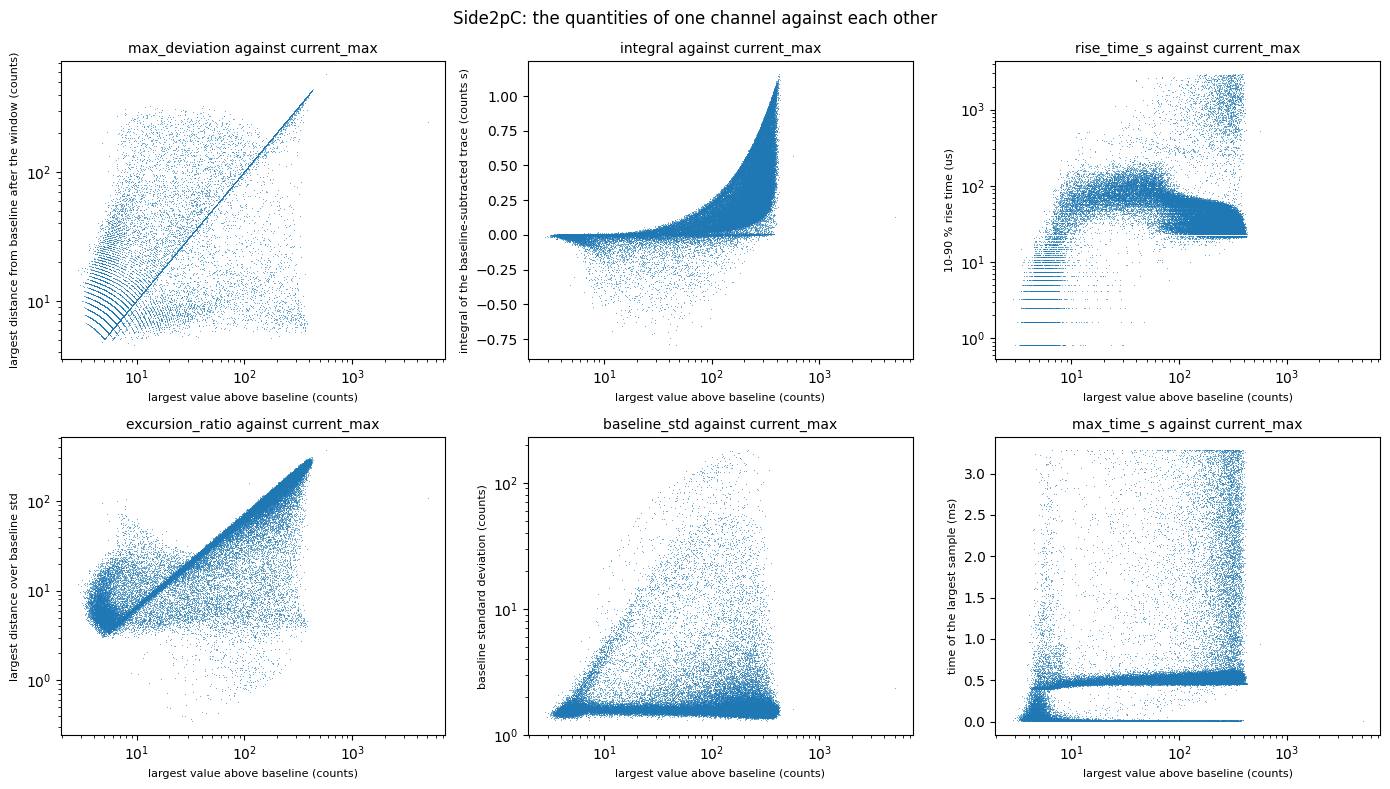

In [5]:
ch = "Side2pC"
pairs = [("max_deviation", "current_max"), ("integral", "current_max"), ("rise_time_s", "current_max"),
         ("excursion_ratio", "current_max"), ("baseline_std", "current_max"), ("max_time_s", "current_max")]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (y, x) in zip(axes.flat, pairs):
    xv, yv = rq[ch, x] * INFO[x][1], rq[ch, y] * INFO[y][1]
    ok = np.isfinite(xv) & np.isfinite(yv) & (xv > 0)
    ax.plot(xv[ok], yv[ok], ",", color="C0", alpha=0.6)
    ax.set_xscale("log")
    if INFO[y][2] == "log":
        ax.set_yscale("log")
    ax.set_xlabel(INFO[x][0], fontsize=8)
    ax.set_ylabel(INFO[y][0], fontsize=8)
    ax.set_title(f"{y} against {x}", fontsize=10)
fig.suptitle(f"{ch}: the quantities of one channel against each other", fontsize=12)
fig.tight_layout()
plt.show()

## Along the series, dump by dump

The median of the baseline and of its scatter, per dump, for every channel: a change here is a change of the electronics or of the environment during the series, not of the pulses. The bottom panel is the fraction of events that have a `rise_time_s` (it is `nan` when the trace never lies below the 10 % level before its peak).

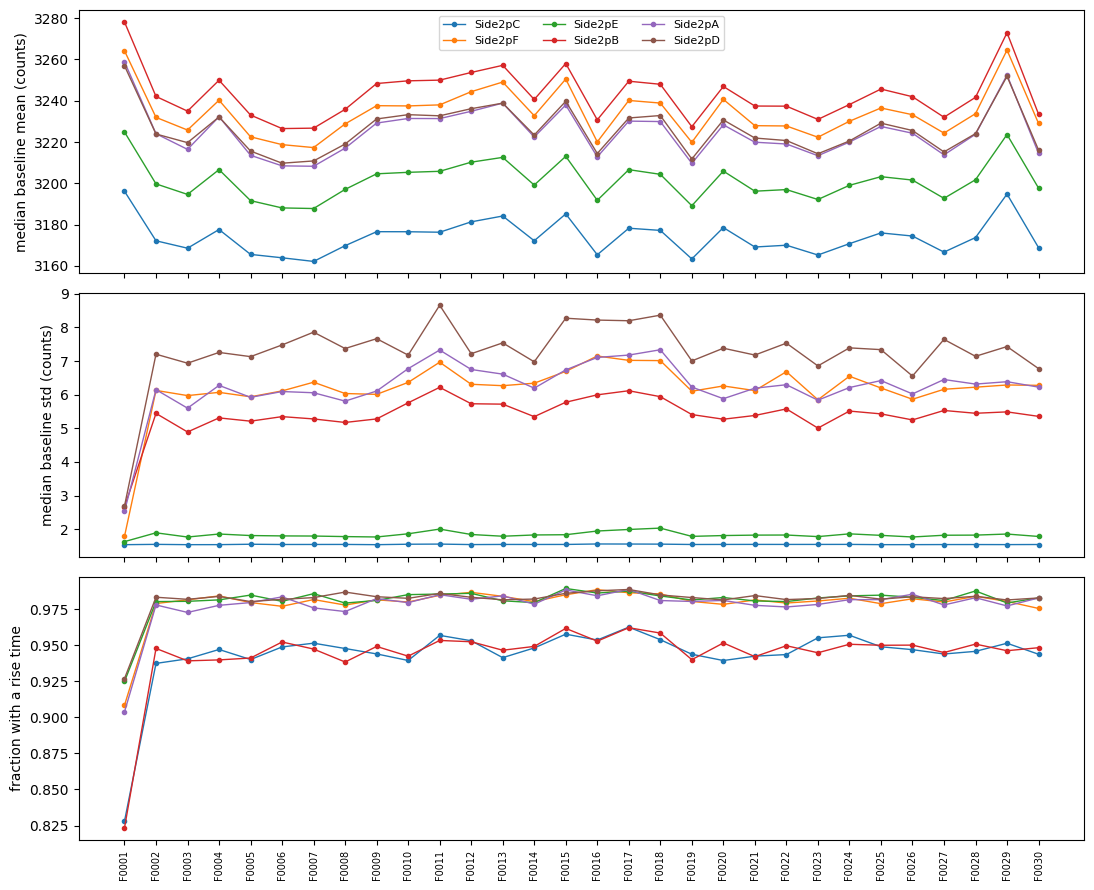

In [6]:
dumps = np.unique(dump)
x = np.arange(len(dumps))
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ch in channels:
    ax1.plot(x, [np.median(rq[ch, "baseline_mean"][dump == d]) for d in dumps], "o-", ms=3, lw=1, label=ch)
    ax2.plot(x, [np.median(rq[ch, "baseline_std"][dump == d]) for d in dumps], "o-", ms=3, lw=1)
    ax3.plot(x, [np.isfinite(rq[ch, "rise_time_s"][dump == d]).mean() for d in dumps], "o-", ms=3, lw=1)
ax1.set_ylabel("median baseline mean (counts)")
ax2.set_ylabel("median baseline std (counts)")
ax3.set_ylabel("fraction with a rise time")
ax3.set_xticks(x)
ax3.set_xticklabels(dumps, rotation=90, fontsize=7)
ax1.legend(fontsize=8, ncol=3)
fig.tight_layout()
plt.show()

**What this shows, and what is next.** All nine quantities of the run are in one `Events` and are plotted here with `numpy` and `matplotlib`; a tenth would need only a line in `INFO`. The units are the ADC's: the amps (`amps_per_adc` in the definition file) are still a placeholder equal to 1.

Not done here: cuts, and looking at the traces behind these numbers. Read a dump of traces with `ds.iter_events(processed=False)` and take the events you want with `ev.select(...)` (see the note on `goldpan` and `goldsluice`).